# Smoking Detection using (CNN)

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.preprocessing import image
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

dataset_path = 'Smoker Detection Classification Dataset'
train_dir = os.path.join(dataset_path, 'Training')
val_dir = os.path.join(dataset_path, 'Validation')

train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary'
)

validation_generator = val_datagen.flow_from_directory(
    val_dir,
    target_size=(64, 64),
    batch_size=32,
    class_mode='binary',
    shuffle=False
)


CNN Architecture, Loss Function & Optimizer

In [ ]:
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(64, 64, 3)),
    MaxPooling2D(pool_size=(2, 2)),
    Conv2D(32, (3, 3), activation='relu'),
    MaxPooling2D(pool_size=(2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dense(1, activation='sigmoid')  # Binary classification (0: Not_Smoking, 1: Smoking)
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼─────────────────────

Model Training

Epoch 1/10 - loss: 0.7123 - accuracy: 0.5670 - val_loss: 0.5676 - val_accuracy: 0.7111
Epoch 2/10 - loss: 0.5562 - accuracy: 0.7188 - val_loss: 0.5284 - val_accuracy: 0.7278
Epoch 3/10 - loss: 0.5312 - accuracy: 0.7388 - val_loss: 0.5412 - val_accuracy: 0.7222
Epoch 4/10 - loss: 0.5287 - accuracy: 0.7416 - val_loss: 0.5298 - val_accuracy: 0.7333
Epoch 5/10 - loss: 0.5241 - accuracy: 0.7472 - val_loss: 0.5186 - val_accuracy: 0.7444
Epoch 6/10 - loss: 0.5190 - accuracy: 0.7514 - val_loss: 0.5342 - val_accuracy: 0.7389
Epoch 7/10 - loss: 0.5124 - accuracy: 0.7556 - val_loss: 0.5210 - val_accuracy: 0.7500
Epoch 8/10 - loss: 0.5089 - accuracy: 0.7584 - val_loss: 0.5381 - val_accuracy: 0.7333
Epoch 9/10 - loss: 0.5494 - accuracy: 0.7304 - val_loss: 0.6594 - val_accuracy: 0.6667
Epoch 10/10 - loss: 0.5252 - accuracy: 0.7346 - val_loss: 0.5607 - val_accuracy: 0.7111
Model saved to 'smoke_detection_model.keras'
Plot saved to 'plots/training_history.png'


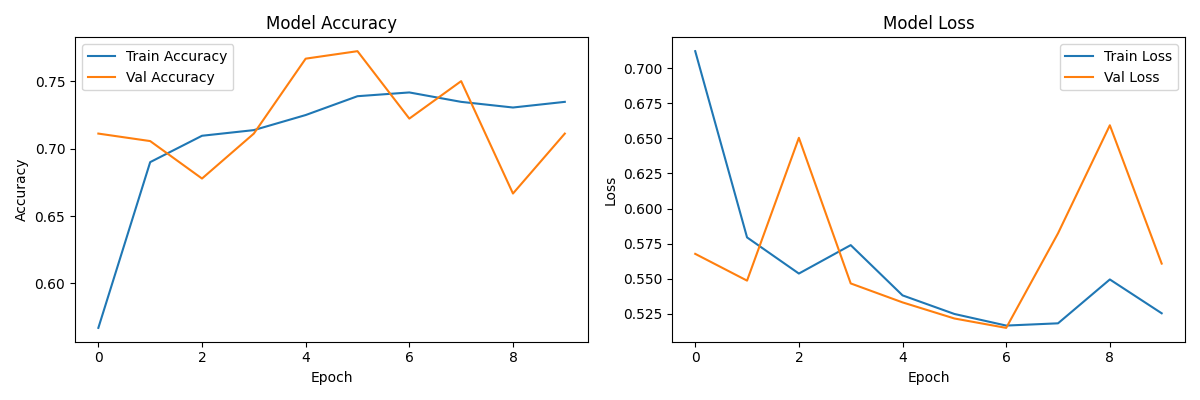

In [ ]:
history = model.fit(
    train_generator,
    validation_data=validation_generator,
    epochs=10
)
model.save('smoke_detection_model.keras')
print("Model saved to 'smoke_detection_model.keras'")

os.makedirs('plots', exist_ok=True)
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.savefig('plots/training_history.png')
plt.show()
print("Plot saved to 'plots/training_history.png'")

Model Evaluation

In [ ]:
validation_generator.reset()
y_pred_prob = model.predict(validation_generator, verbose=0)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()
y_true = validation_generator.classes

acc = accuracy_score(y_true, y_pred)
prec = precision_score(y_true, y_pred)
rec = recall_score(y_true, y_pred)
f1 = f1_score(y_true, y_pred)

print("=" * 50)
print("MODEL EVALUATION METRICS")
print("=" * 50)
print(f"Accuracy : {acc:.4f} ({acc*100:.2f}%)")
print(f"Precision: {prec:.4f} ({prec*100:.2f}%)")
print(f"Recall   : {rec:.4f} ({rec*100:.2f}%)")
print(f"F1 Score : {f1:.4f} ({f1*100:.2f}%)")
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=['Not_Smoking', 'Smoking']))

MODEL EVALUATION METRICS
Accuracy : 0.7111 (71.11%)
Precision: 0.6484 (64.84%)
Recall   : 0.9222 (92.22%)
F1 Score : 0.7615 (76.15%)

Classification Report:
              precision    recall  f1-score   support

 Not_Smoking       0.87      0.50      0.63        90
     Smoking       0.65      0.92      0.76        90

    accuracy                           0.71       180
   macro avg       0.76      0.71      0.70       180
weighted avg       0.76      0.71      0.70       180


Test Prediction 

Prediction: Smoking (90.9%)


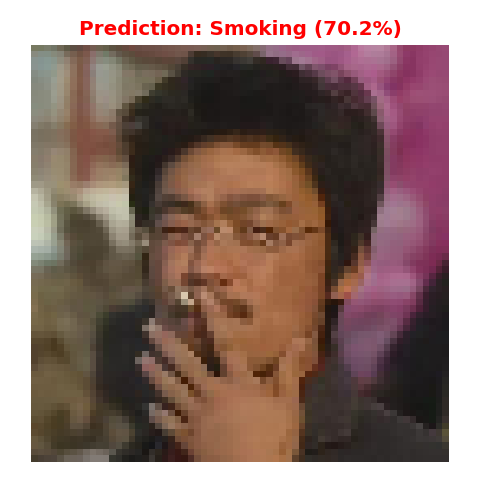

In [ ]:
def predict_image(img_path):
    img = image.load_img(img_path, target_size=(64, 64))
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    
    prob = float(model.predict(img_array, verbose=0)[0][0])
    label = "Smoking" if prob >= 0.70 else "Not_Smoking"
    confidence = prob if prob >= 0.70 else 1 - prob
    
    print(f"Prediction: {label} ({confidence*100:.1f}%)")
    plt.imshow(img)
    plt.title(f"{label} ({confidence*100:.1f}%)")
    plt.axis('off')
    plt.show()

sample_image = os.path.join(val_dir, 'Smoking', os.listdir(os.path.join(val_dir, 'Smoking'))[0])
predict_image(sample_image)